# 1. EDA & Feature Engineering
**Smart Grid Electricity Demand Prediction**

Ee notebook-il cheyyunnath:
1. Raw data load cheyyuka
2. Data clean cheyyuka (missing values, duplicates, dtypes check)
3. Avashyamillatha columns remove cheyyuka (data leakage columns)
4. EDA cheyyuka (patterns manasilakan)
5. Puthiya features add cheyyuka (feature engineering)
6. Final clean dataset save cheyyuka -> `processed_data.csv`

## 1.1 Import libraries

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

DATA_PATH = 'England_Wales_Electricity_2021_2025_final.csv'

## 1.2 Load data

In [8]:
df = pd.read_csv(DATA_PATH, parse_dates=['Date'])
print('Shape:', df.shape)
df.head()

Shape: (86976, 34)


,Date,Time_Period,National_Demand,Transmission_Demand,Electricity_Demand,Wind_Generation,Wind_Capacity,Solar_Generation,Solar_Capacity,Non_BM_Storage,...,Day_of_Week,Hour,Is_Weekend,Quarter,Day_of_Year,Week_of_Year,Demand_Previous_30min,Demand_Previous_1hr,Demand_Previous_24hr,Demand_Previous_7days
0,2021-01-15,1,28471,30412,25826,699,6527,0,13527,0,...,4,0,0,1,15,2,25972.0,27107.0,24797.0,27155.0
1,2021-01-15,2,28940,31017,26297,703,6527,0,13527,0,...,4,0,0,1,15,2,25826.0,25972.0,25251.0,27557.0
2,2021-01-15,3,28689,30798,26133,624,6527,0,13527,0,...,4,1,0,1,15,2,26297.0,25826.0,24932.0,27375.0
3,2021-01-15,4,28178,30112,25682,571,6527,0,13527,0,...,4,1,0,1,15,2,26133.0,26297.0,24397.0,26883.0
4,2021-01-15,5,27821,29989,25363,548,6527,0,13527,0,...,4,2,0,1,15,2,25682.0,26133.0,23964.0,26335.0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86976 entries, 0 to 86975
Data columns (total 34 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   Date                                  86976 non-null  datetime64[ns]
 1   Time_Period                           86976 non-null  int64         
 2   National_Demand                       86976 non-null  int64         
 3   Transmission_Demand                   86976 non-null  int64         
 4   Electricity_Demand                    86976 non-null  int64         
 5   Wind_Generation                       86976 non-null  int64         
 6   Wind_Capacity                         86976 non-null  int64         
 7   Solar_Generation                      86976 non-null  int64         
 8   Solar_Capacity                        86976 non-null  int64         
 9   Non_BM_Storage                        86976 non-null  int64         
 10

## 1.3 Data cleaning
### Check missing values

In [10]:
print(df.isnull().sum()[df.isnull().sum() > 0])
print('\nTotal missing:', df.isnull().sum().sum())

Series([], dtype: int64)

Total missing: 0


### Check duplicates

In [11]:
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates()

Duplicate rows: 0


### Create a proper Datetime column (Date + Time_Period -> half-hourly timestamp)

In [12]:
df['Datetime'] = df['Date'] + pd.to_timedelta((df['Time_Period'] - 1) * 30, unit='m')
df = df.sort_values('Datetime').reset_index(drop=True)
df[['Date', 'Time_Period', 'Datetime']].head()

,Date,Time_Period,Datetime
0,2021-01-15,1,2021-01-15 00:00:00
1,2021-01-15,2,2021-01-15 00:30:00
2,2021-01-15,3,2021-01-15 01:00:00
3,2021-01-15,4,2021-01-15 01:30:00
4,2021-01-15,5,2021-01-15 02:00:00


### Handle any remaining nulls in lag columns (first few rows won't have lag history)

In [13]:
lag_cols = ['Demand_Previous_30min', 'Demand_Previous_1hr', 'Demand_Previous_24hr', 'Demand_Previous_7days']
print(df[lag_cols].isnull().sum())
df = df.dropna(subset=lag_cols).reset_index(drop=True)
print('Shape after dropping null lags:', df.shape)

Demand_Previous_30min    0
Demand_Previous_1hr      0
Demand_Previous_24hr     0
Demand_Previous_7days    0
dtype: int64
Shape after dropping null lags: (86976, 35)


## 1.4 Remove unnecessary columns

**Enthinu remove cheyyunnu:**
- Interconnector flow columns (France, Netherlands, Belgium, Norway, etc.) — grid demand-nte direct predictor alla, aduthu bandhamillatha external factors aanu, correlation weak aanu
- `Non_BM_Storage`, `Pumped_Storage_Pumping` — storage operations aanu, demand-ne directly predict cheyyan sahayikkilla
- `National_Demand`, `Transmission_Demand` — ivyum almost namude target `Electricity_Demand`-inu same time-il aanu measure cheyyunnath (near-duplicate/leakage), so ithu ozhivakkanam

In [14]:
drop_cols = [
    'France_Interconnector_Flow', 'France_Interconnector_2_Flow',
    'Netherlands_Interconnector_Flow', 'Northern_Ireland_Interconnector_Flow',
    'East_West_Interconnector_Flow', 'Belgium_Interconnector_Flow',
    'Norway_Interconnector_Flow', 'France_ElecLink_Flow',
    'Denmark_Interconnector_Flow', 'Ireland_Greenlink_Flow',
    'Non_BM_Storage', 'Pumped_Storage_Pumping',
    'National_Demand', 'Transmission_Demand',  # near-duplicate of target -> leakage
]
df = df.drop(columns=drop_cols)
print('Remaining columns:', df.shape[1])
df.columns.tolist()

Remaining columns: 21


['Date',
 'Time_Period',
 'Electricity_Demand',
 'Wind_Generation',
 'Wind_Capacity',
 'Solar_Generation',
 'Solar_Capacity',
 'Year',
 'Month',
 'Day',
 'Day_of_Week',
 'Hour',
 'Is_Weekend',
 'Quarter',
 'Day_of_Year',
 'Week_of_Year',
 'Demand_Previous_30min',
 'Demand_Previous_1hr',
 'Demand_Previous_24hr',
 'Demand_Previous_7days',
 'Datetime']

## 1.5 EDA — Understand the patterns

### Daily demand trend (2021-2025)

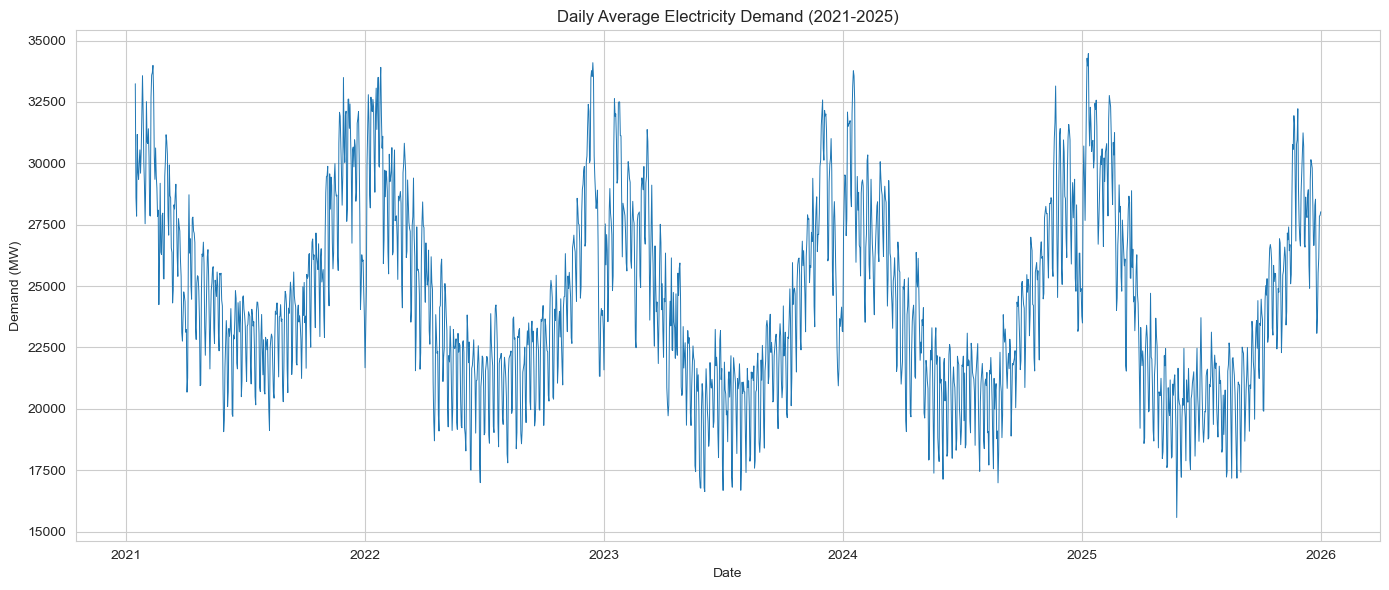

In [15]:
daily = df.groupby('Date')['Electricity_Demand'].mean().reset_index()
plt.figure()
plt.plot(daily['Date'], daily['Electricity_Demand'], linewidth=0.7)
plt.title('Daily Average Electricity Demand (2021-2025)')
plt.xlabel('Date'); plt.ylabel('Demand (MW)')
plt.tight_layout(); plt.show()

### Hourly pattern (daily double-peak)

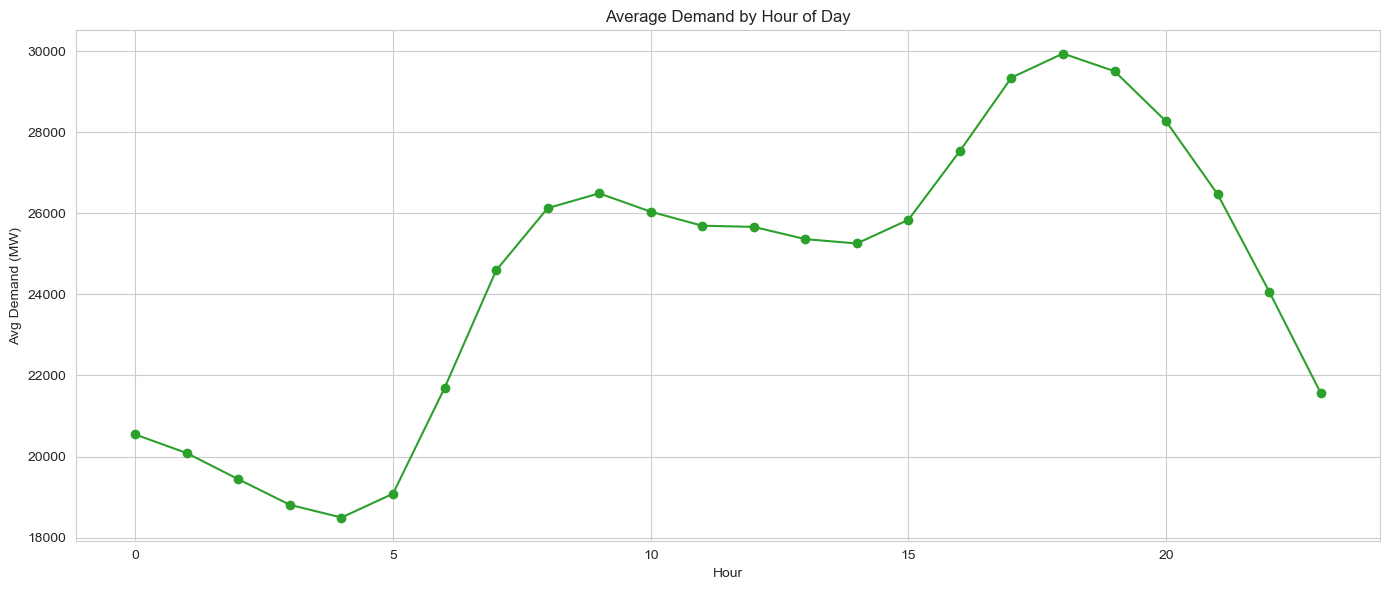

In [16]:
hourly = df.groupby('Hour')['Electricity_Demand'].mean()
plt.figure()
hourly.plot(marker='o', color='#2ca02c')
plt.title('Average Demand by Hour of Day')
plt.xlabel('Hour'); plt.ylabel('Avg Demand (MW)')
plt.tight_layout(); plt.show()

### Monthly seasonality

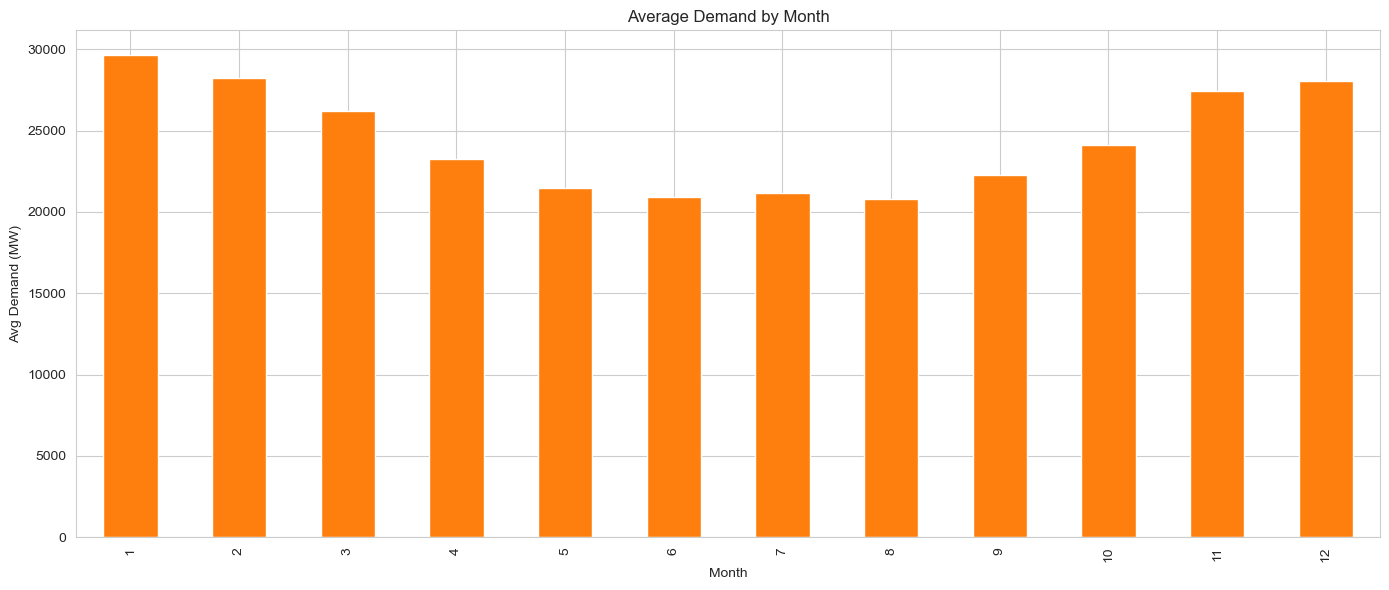

In [17]:
monthly = df.groupby('Month')['Electricity_Demand'].mean()
plt.figure()
monthly.plot(kind='bar', color='#ff7f0e')
plt.title('Average Demand by Month')
plt.xlabel('Month'); plt.ylabel('Avg Demand (MW)')
plt.tight_layout(); plt.show()

### Weekday vs Weekend

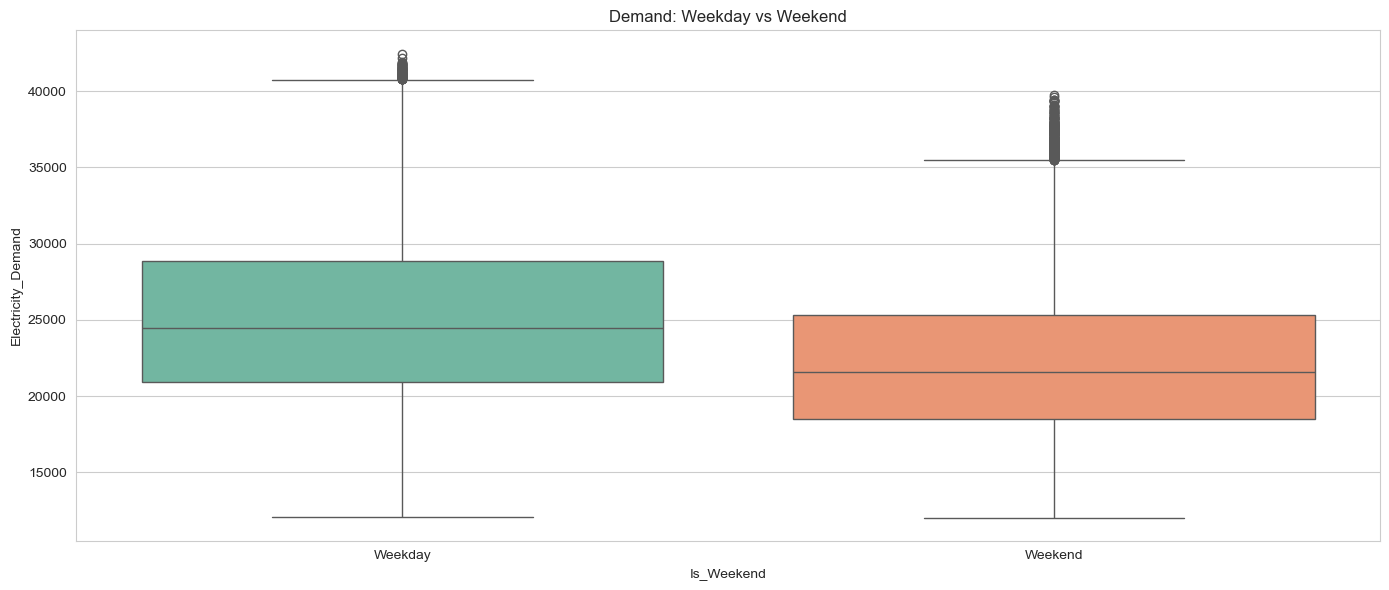

In [18]:
plt.figure()
sns.boxplot(data=df, x='Is_Weekend', y='Electricity_Demand', hue='Is_Weekend', palette='Set2', legend=False)
plt.xticks([0, 1], ['Weekday', 'Weekend'])
plt.title('Demand: Weekday vs Weekend')
plt.tight_layout(); plt.show()

### Correlation with target

Electricity_Demand       1.000000
Demand_Previous_30min    0.989073
Demand_Previous_1hr      0.959606
Demand_Previous_24hr     0.911442
Demand_Previous_7days    0.903902
Hour                     0.437160
Time_Period              0.436742
Wind_Generation          0.094683
Day                     -0.025969
Day_of_Year             -0.087365
Month                   -0.087469
Quarter                 -0.089263
Solar_Capacity          -0.090148
Year                    -0.090418
Week_of_Year            -0.091076
Wind_Capacity           -0.096826
Solar_Generation        -0.144218
Day_of_Week             -0.189108
Is_Weekend              -0.232110
Name: Electricity_Demand, dtype: float64


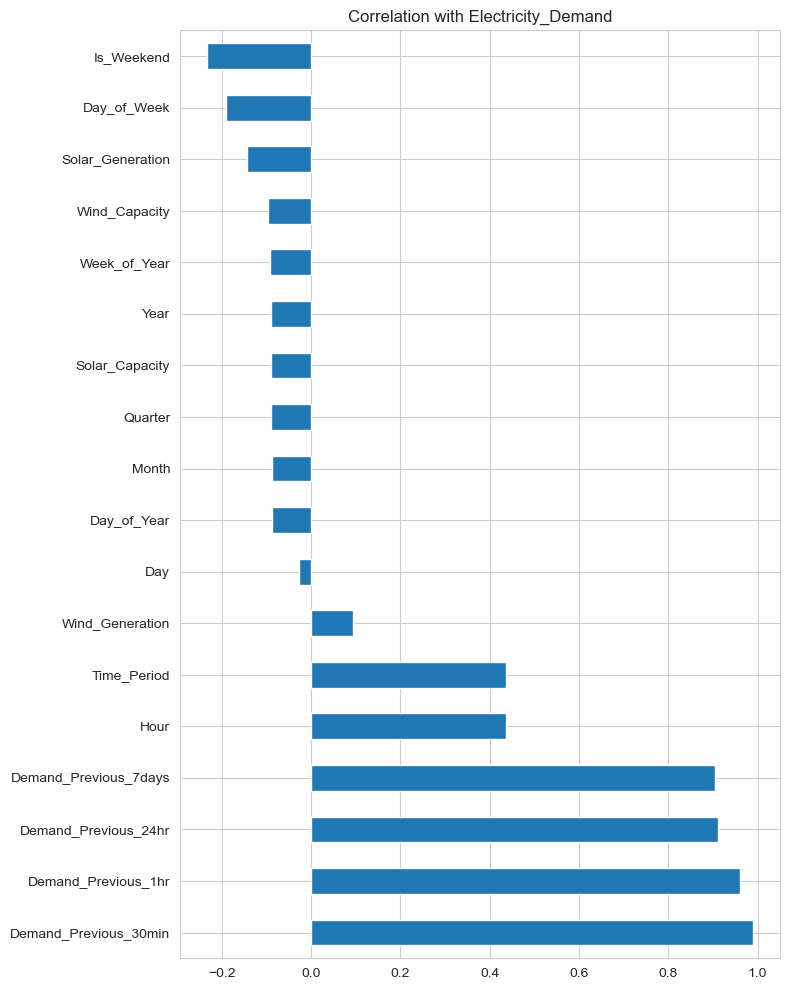

In [19]:
corr = df.select_dtypes(include=[np.number]).corr()['Electricity_Demand'].sort_values(ascending=False)
print(corr)

plt.figure(figsize=(8, 10))
corr.drop('Electricity_Demand').plot(kind='barh')
plt.title('Correlation with Electricity_Demand')
plt.tight_layout(); plt.show()

## 1.6 Feature Engineering

**Puthiya features add cheyyunnu:**
- Cyclical encoding for Hour, Month, Day_of_Week (sin/cos) — ithu 23:00-um 00:00-um close aanu ennu model-inu manasilakan sahayikkum (plain numbers vachal 23-um 0-um far apart ayittanu model kanunnath)

In [20]:
df['Hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24)
df['Hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24)
df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)
df['DoW_sin'] = np.sin(2 * np.pi * df['Day_of_Week'] / 7)
df['DoW_cos'] = np.cos(2 * np.pi * df['Day_of_Week'] / 7)

print('New columns added:', ['Hour_sin','Hour_cos','Month_sin','Month_cos','DoW_sin','DoW_cos'])

New columns added: ['Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'DoW_sin', 'DoW_cos']


## 1.7 Save the cleaned + engineered dataset

In [22]:
df.to_csv('England_Wales_Electricity_2021_2025_for_prediction.csv', index=False)
print('Saved processed_data.csv with shape:', df.shape)
print('\nFinal columns:')
print(df.columns.tolist())

Saved processed_data.csv with shape: (86976, 27)

Final columns:
['Date', 'Time_Period', 'Electricity_Demand', 'Wind_Generation', 'Wind_Capacity', 'Solar_Generation', 'Solar_Capacity', 'Year', 'Month', 'Day', 'Day_of_Week', 'Hour', 'Is_Weekend', 'Quarter', 'Day_of_Year', 'Week_of_Year', 'Demand_Previous_30min', 'Demand_Previous_1hr', 'Demand_Previous_24hr', 'Demand_Previous_7days', 'Datetime', 'Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'DoW_sin', 'DoW_cos']
